## Загрузка датасета

In [140]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer

data = fetch_20newsgroups(subset="all")
texts, y_true = data.data, data.target

## Эмбеддинг

In [141]:
vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(texts)

# Изменение размерности массива

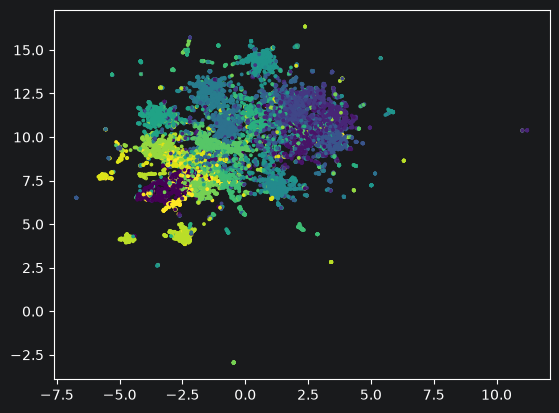

In [142]:
import umap

X_umap = umap.UMAP(min_dist=0.0).fit_transform(X)

plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_true, s=3)
plt.show()

Видно что в центре кластера пересекаются изза изменения размерности

### Кластеризуем 20 новостей

ARI: 0.19756811066457142
NMI: 0.3772083422682816


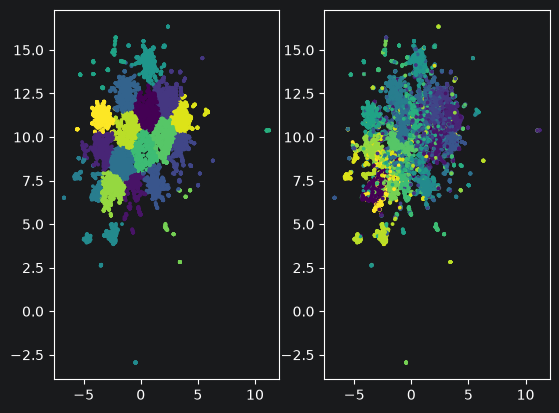

In [143]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

clusters_count = max(y_true) + 1

k_means = KMeans(n_clusters=clusters_count).fit_predict(X_umap)

print("ARI:", adjusted_rand_score(y_true, labels))
print("NMI:", normalized_mutual_info_score(y_true, labels))

plt.subplot(1, 2, 1)
plt.scatter(X_umap[:, 0], X_umap[:, 1], c=k_means, s=3)
plt.subplot(1, 2, 2)
plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_true, s=3)
plt.show()